In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\wasim\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.impute import SimpleImputer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
   accuracy_score,
   precision_score,
   recall_score, 
   f1_score,
   confusion_matrix,
   classification_report
)

In [3]:
df = pd.read_csv("C:\\Users\\wasim\\Downloads\\customer_churn_prediction.csv")

In [4]:
df.head()

,CustomerID,Age,Tenure_Months,MonthlyCharges,TotalCharges,ContractType,InternetService,PaymentMethod,TechSupport,OnlineSecurity,Streaming,SupportCalls,LatePayments,SatisfactionScore,Churn
0,10001,56,23,62.50,1481.87,Month-to-month,Fiber optic,Electronic check,No,Yes,Yes,6,5,6,1
1,10002,69,63,69.51,4636.71,Month-to-month,Fiber optic,Credit card,No,No,No,3,4,3,1
2,10003,46,15,44.97,660.14,Month-to-month,Fiber optic,Bank transfer,No,No,No,2,0,7,0
3,10004,32,25,117.83,2730.46,Month-to-month,DSL,Electronic check,Yes,No,No,2,0,3,0
4,10005,60,17,69.57,1272.45,Month-to-month,Fiber optic,Bank transfer,Yes,No,Yes,3,2,9,0


In [5]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)
print("\nData Types:")
print(df.dtypes)

Shape: (1200, 15)

Columns:
Index(['CustomerID', 'Age', 'Tenure_Months', 'MonthlyCharges', 'TotalCharges',
       'ContractType', 'InternetService', 'PaymentMethod', 'TechSupport',
       'OnlineSecurity', 'Streaming', 'SupportCalls', 'LatePayments',
       'SatisfactionScore', 'Churn'],
      dtype='str')

Data Types:
CustomerID             int64
Age                    int64
Tenure_Months          int64
MonthlyCharges       float64
TotalCharges         float64
ContractType             str
InternetService          str
PaymentMethod            str
TechSupport              str
OnlineSecurity           str
Streaming                str
SupportCalls           int64
LatePayments           int64
SatisfactionScore      int64
Churn                  int64
dtype: object


In [6]:
df.isnull().sum()

CustomerID            0
Age                   0
Tenure_Months         0
MonthlyCharges       24
TotalCharges         24
ContractType          0
InternetService       0
PaymentMethod         0
TechSupport          24
OnlineSecurity       24
Streaming             0
SupportCalls          0
LatePayments          0
SatisfactionScore     0
Churn                 0
dtype: int64

In [7]:
print(df["Churn"].value_counts())
print("\nPercentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
0    941
1    259
Name: count, dtype: int64

Percentage:
Churn
0    78.416667
1    21.583333
Name: proportion, dtype: float64


In [8]:
X = df.drop("Churn", axis=1)
y = df["Churn"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1200, 14)
y shape: (1200,)


In [9]:
y = df["Churn"]

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         1200 non-null   int64  
 1   Age                1200 non-null   int64  
 2   Tenure_Months      1200 non-null   int64  
 3   MonthlyCharges     1176 non-null   float64
 4   TotalCharges       1176 non-null   float64
 5   ContractType       1200 non-null   str    
 6   InternetService    1200 non-null   str    
 7   PaymentMethod      1200 non-null   str    
 8   TechSupport        1176 non-null   str    
 9   OnlineSecurity     1176 non-null   str    
 10  Streaming          1200 non-null   str    
 11  SupportCalls       1200 non-null   int64  
 12  LatePayments       1200 non-null   int64  
 13  SatisfactionScore  1200 non-null   int64  
 14  Churn              1200 non-null   int64  
dtypes: float64(2), int64(7), str(6)
memory usage: 186.3 KB


In [11]:
df.describe()

,CustomerID,Age,Tenure_Months,MonthlyCharges,TotalCharges,SupportCalls,LatePayments,SatisfactionScore,Churn
count,1200.000000,1200.000000,1200.000000,1176.000000,1176.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,10600.500000,44.151667,35.715833,75.496148,2675.229337,4.020000,2.484167,5.407500,0.215833
std,346.554469,15.318754,20.614539,32.081977,2019.402087,2.543946,1.691784,2.857431,0.411571
min,10001.000000,18.000000,1.000000,20.020000,24.140000,0.000000,0.000000,1.000000,0.000000
25%,10300.750000,31.000000,18.000000,47.000000,1071.425000,2.000000,1.000000,3.000000,0.000000
50%,10600.500000,44.000000,35.500000,76.920000,2232.235000,4.000000,3.000000,5.000000,0.000000
75%,10900.250000,57.000000,53.000000,103.435000,3890.042500,6.000000,4.000000,8.000000,0.000000
max,11200.000000,70.000000,72.000000,129.970000,9489.890000,8.000000,5.000000,10.000000,1.000000


In [12]:
print(df.columns)

Index(['CustomerID', 'Age', 'Tenure_Months', 'MonthlyCharges', 'TotalCharges',
       'ContractType', 'InternetService', 'PaymentMethod', 'TechSupport',
       'OnlineSecurity', 'Streaming', 'SupportCalls', 'LatePayments',
       'SatisfactionScore', 'Churn'],
      dtype='str')


In [13]:
X = X.drop("CustomerID", axis=1)

In [14]:
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns

categorical_features = X.select_dtypes(include=["object"]).columns

print("Numerical Features:")
print(list(numerical_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['Age', 'Tenure_Months', 'MonthlyCharges', 'TotalCharges', 'SupportCalls', 'LatePayments', 'SatisfactionScore']

Categorical Features:
['ContractType', 'InternetService', 'PaymentMethod', 'TechSupport', 'OnlineSecurity', 'Streaming']


C:\Users\wasim\AppData\Local\Temp\ipykernel_36420\3392129230.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [16]:
X = df.drop(["Churn", "CustomerID"], axis=1)
y = df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (1200, 13)
y shape: (1200,)


In [17]:
from sklearn.model_selection import train_test_split
X_train, Xtest, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (960, 13)
Testing data: (240, 13)


In [18]:
numerical_pipeline = Pipeline ([
    ("imputer", SimpleImputer(strategy="median")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [19]:
class_weight="balanced"

In [20]:
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    max_depth=10
)

In [21]:

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [22]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [23]:
print(preprocessor)

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['Age', 'Tenure_Months', 'MonthlyCharges', 'TotalCharges',
       'SupportCalls', 'LatePayments', 'SatisfactionScore'],
      dtype='str')),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['ContractType', 'InternetService', 'PaymentMethod', 'TechSupport',
       'OnlineSecurity', 'Streaming'],
      dtype='str'))])


In [24]:
pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", model)
])

print("Pipeline created successfully!")

Pipeline created successfully!


In [25]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Age','Tenure_Months','MonthlyCharges',...,'SupportCalls','LatePayments', 'SatisfactionScore']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

In [26]:
y_pred = pipeline.predict(X_test)

In [27]:
print(y_pred[:20])

[0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 1]


In [28]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.7458333333333333


In [29]:
print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 74.58 %


In [30]:
precision = precision_score(y_test, y_pred)
print("Precision:", round(precision, 3))

Precision: 0.4


In [31]:
recall = recall_score(y_test, y_pred)
print("Recall:", round(recall, 3))

Recall: 0.346


In [32]:
f1 = f1_score(y_test, y_pred)
print("F1 Score:", round(f1, 3))

F1 Score: 0.371


In [33]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.86      0.84       188
           1       0.40      0.35      0.37        52

    accuracy                           0.75       240
   macro avg       0.61      0.60      0.61       240
weighted avg       0.73      0.75      0.74       240



In [34]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[161  27]
 [ 34  18]]


In [35]:
rf_model = pipeline.named_steps["model"]

In [36]:
rf_model = pipeline.named_steps[
  "preprocessing"
].get_feature_names_out()

In [37]:
new_customer = pd.DataFrame({
    "Age": [35],
    "Tenure_Months": [8],
    "MonthlyCharges": [95.50],
    "TotalCharges": [764.00],
    "ContractType": ["Month-to-month"],
    "InternetService": ["Fiber optic"],
    "PaymentMethod": ["Electronic check"],
    "TechSupport": ["No"],
    "OnlineSecurity": ["No"],
    "Streaming": ["Yes"],
    "SupportCalls": [6],
    "LatePayments": [3],
    "SatisfactionScore": [4]
})

In [38]:
prediction = pipeline.predict(new_customer)

print("Prediction:", prediction)

Prediction: [1]


In [39]:
if prediction[0] == 1:
    print("Customer is likely to churn.")
else:
    print("Customer is unlikely to churn.")

Customer is likely to churn.


In [40]:
probability = pipeline.predict_proba(new_customer)

print(probability)

[[0.20218538 0.79781462]]


In [41]:
churn_probability = probability[0][1]

print("Churn Probability:", round(churn_probability * 100, 2), "%")

Churn Probability: 79.78 %


In [42]:
df.head()

,CustomerID,Age,Tenure_Months,MonthlyCharges,TotalCharges,ContractType,InternetService,PaymentMethod,TechSupport,OnlineSecurity,Streaming,SupportCalls,LatePayments,SatisfactionScore,Churn
0,10001,56,23,62.50,1481.87,Month-to-month,Fiber optic,Electronic check,No,Yes,Yes,6,5,6,1
1,10002,69,63,69.51,4636.71,Month-to-month,Fiber optic,Credit card,No,No,No,3,4,3,1
2,10003,46,15,44.97,660.14,Month-to-month,Fiber optic,Bank transfer,No,No,No,2,0,7,0
3,10004,32,25,117.83,2730.46,Month-to-month,DSL,Electronic check,Yes,No,No,2,0,3,0
4,10005,60,17,69.57,1272.45,Month-to-month,Fiber optic,Bank transfer,Yes,No,Yes,3,2,9,0


##  Churn by contract type

In [43]:
contract_analysis = df.groupby(
    "ContractType"
).agg(
    Total_Customers=("Churn", "count"),
    Churned_Customers=("Churn", "sum")
)
contract_analysis["Churn_Rate"] = (
    contract_analysis["Churned_Customers"] /
    contract_analysis["Total_Customers"] * 100
)
display(contract_analysis.round(2))

,Total_Customers,Churned_Customers,Churn_Rate
ContractType,,,
Month-to-month,650,181,27.85
One year,317,47,14.83
Two year,233,31,13.30


## payment method

In [44]:
payment_analysis = df.groupby(
    "PaymentMethod"
).agg(
    Total_Customers=("Churn", "count"),
    Churned_Customers=("Churn", "sum")
)
payment_analysis["Churn_Rate"] = (
    payment_analysis["Churned_Customers"] /
    payment_analysis["Total_Customers"] * 100
)
display(payment_analysis.sort_values(
    "Churn_Rate",
    ascending=False
).round(2))

,Total_Customers,Churned_Customers,Churn_Rate
PaymentMethod,,,
Electronic check,479,121,25.26
Credit card,299,62,20.74
Bank transfer,235,47,20.00
Mailed check,187,29,15.51


## internet service

In [45]:
internet_analysis = df.groupby(
    "InternetService"
).agg(
    Total_Customers=("Churn", "count"),
    Churned_Customers=("Churn", "sum")
)
internet_analysis["Churn_Rate"] = (
    internet_analysis["Churned_Customers"] /
    internet_analysis["Total_Customers"] * 100
)
display(internet_analysis.sort_values(
    "Churn_Rate",
    ascending=False
).round(2))

,Total_Customers,Churned_Customers,Churn_Rate
InternetService,,,
Fiber optic,586,152,25.94
DSL,450,82,18.22
No,164,25,15.24


## Satisfaction score vs churn

In [46]:
satisfaction_analysis = df.groupby(
    "Churn"
)["SatisfactionScore"].agg(
    ["count", "mean", "median"]
)
satisfaction_analysis.index = [
    "Retained",
    "Churned"
]
display(satisfaction_analysis.round(2))

,count,mean,median
Retained,941,5.54,6.0
Churned,259,4.91,5.0


## support calls vs churn

In [47]:
support_analysis = df.groupby(
    "SupportCalls"
).agg(
    Total_Customers=("Churn", "count"),
    Churned_Customers=("Churn", "sum")
)
support_analysis["Churn_Rate"] = (
    support_analysis["Churned_Customers"] /
   support_analysis["Total_Customers"] * 100
)
display(support_analysis.round(2))

,Total_Customers,Churned_Customers,Churn_Rate
SupportCalls,,,
0,118,15,12.71
1,138,24,17.39
2,134,18,13.43
3,138,17,12.32
4,143,33,23.08
5,140,27,19.29
6,126,32,25.40
7,128,47,36.72
8,135,46,34.07


## Monthly charges vs churn

In [48]:
df["Charge_Category"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 40, 70, 100, 130],
    labels=[
        "Low Charges",
        "Medium Charges",
        "High Charges",
        "Very High Charges"
    ]
)
charge_analysis = df.groupby(
    "Charge_Category",
    observed=True
).agg(
    Total_Customers=("Churn", "count"),
    Churned_Customers=("Churn", "sum"),
    Average_Charges=("MonthlyCharges", "mean")
)
charge_analysis["Churn_Rate"] = (
    charge_analysis["Churned_Customers"] /
    charge_analysis["Total_Customers"] * 100
)
display(charge_analysis.round(2))

,Total_Customers,Churned_Customers,Average_Charges,Churn_Rate
Charge_Category,,,,
Low Charges,228,38,30.01,16.67
Medium Charges,289,58,55.49,20.07
High Charges,320,67,84.69,20.94
Very High Charges,339,91,114.46,26.84


## tenure group analysis

In [49]:
df["Tenure_Category"] = pd.cut(
    df["Tenure_Months"],
    bins=[0, 40, 70, 100, 130],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-72 Months"
    ]
)
Tenure_analysis = df.groupby(
    "Tenure_Category",
    observed=True
).agg(
    Total_Customers=("Churn", "count"),
    Churned_Customers=("Churn", "sum"),
  
)
Tenure_analysis["Churn_Rate"] = (
  Tenure_analysis["Churned_Customers"] /
   Tenure_analysis["Total_Customers"] * 100
)
display(Tenure_analysis.round(2))

,Total_Customers,Churned_Customers,Churn_Rate
Tenure_Category,,,
0-12 Months,695,165,23.74
13-24 Months,473,88,18.60
25-48 Months,32,6,18.75


## visualize business

<function matplotlib.pyplot.show(close=None, block=None)>

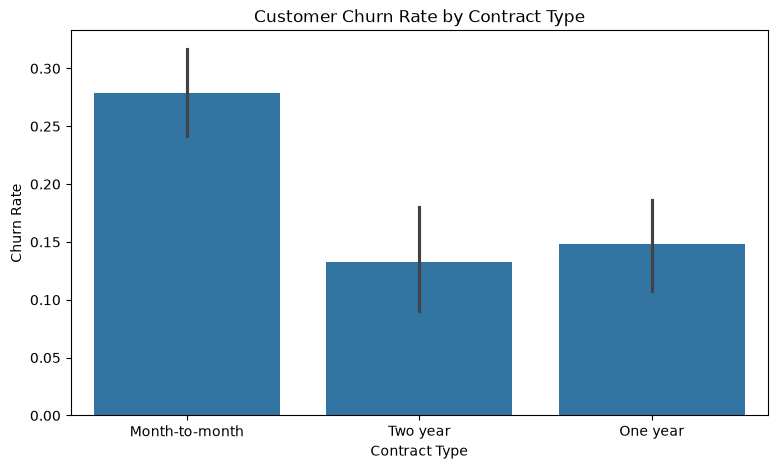

In [50]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=df,
    x="ContractType",
    y="Churn",
    estimator="mean"
)
plt.title("Customer Churn Rate by Contract Type")
plt.ylabel("Churn Rate")
plt.xlabel("Contract Type")
plt.show

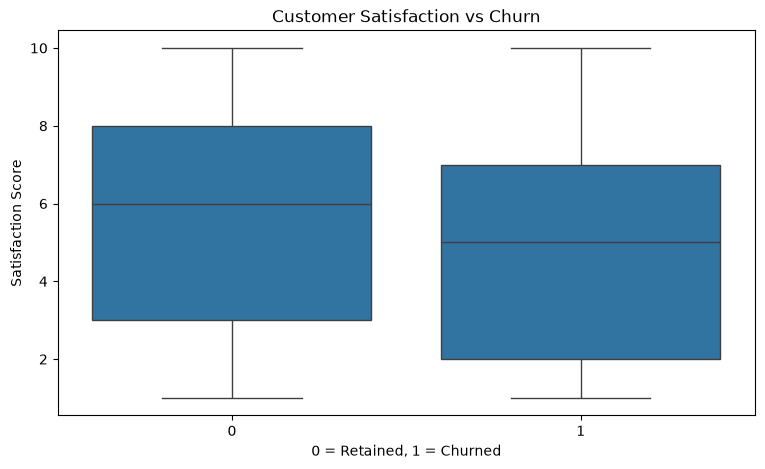

In [51]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="Churn",
    y="SatisfactionScore"
)
plt.title("Customer Satisfaction vs Churn")
plt.xlabel("0 = Retained, 1 = Churned")
plt.ylabel("Satisfaction Score")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

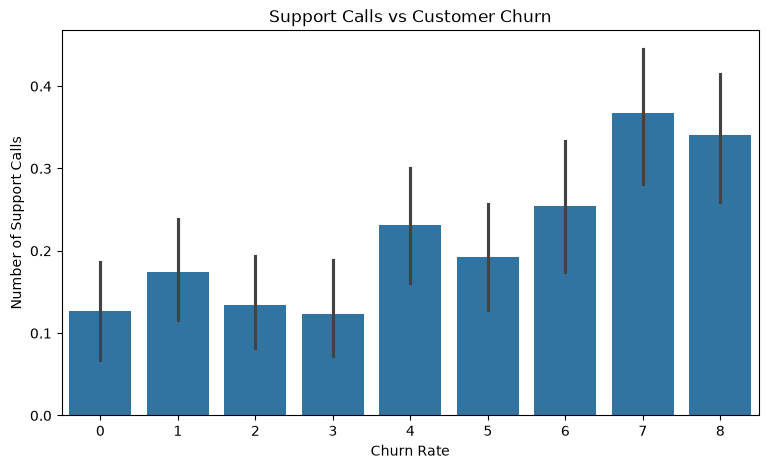

In [52]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=df,
    x="SupportCalls",
    y="Churn",

)
plt.title("Support Calls vs Customer Churn")
plt.ylabel("Number of Support Calls")
plt.xlabel("Churn Rate")
plt.show